# Лаба 3. Вероятностный алгоритм Чипполы

Нужно решить уравнение $x^2 \equiv a \pmod p$ при нечётном простом $p$, $(a,p)=1$ и $\left(\frac{a}{p}\right)=1$. Достаточно найти один корень $x_0$: второй равен $-x_0$.

**Алгоритм Чипполы.**
1. Случайно выбрать $b$, $0\le b\le p-1$, такое что $\left(\frac{b^2-4a}{p}\right)=-1$.
2. Положить $f(y)=y^2-by+a\in\mathbb Z_p[y]$.
3. $x_0$ — остаток от деления $y^{(p+1)/2}$ на $f(y)$; это константа.

Многочлен $f$ неприводим, поэтому $\mathbb Z_p[y]/(f)$ — поле из $p^2$ элементов; в нём $y^p=b-y$, откуда $y^{p+1}=y(b-y)=a$.

In [2]:
import importlib, glob, os, subprocess, sys

REPO_URL = "https://github.com/KseniaKov/methods-programming_lab.git"
MODULE = "cipolla"

try:
    importlib.import_module(MODULE)
except ModuleNotFoundError:
    found = False
    if REPO_URL:
        try:
            subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=True)
            paths = glob.glob(f"repo/**/{MODULE}.py", recursive=True)
            if paths:
                sys.path.append(os.path.dirname(os.path.abspath(paths[0])))
                found = True
        except (subprocess.CalledProcessError, FileNotFoundError):
            print("Не удалось клонировать репозиторий")
    if not found:
        from google.colab import files
        print(f"Выберите файл {MODULE}.py с компьютера")
        files.upload()
    importlib.invalidate_caches()
    importlib.import_module(MODULE)
print(f"{MODULE}.py найден")

cipolla.py найден
cipolla.py найден


In [3]:
import random, time
import matplotlib.pyplot as plt
from cipolla import (cipolla, sqrt_mod, sqrt_3mod4, fp2_mul, fp2_pow,
                     legendre_euler, is_probable_prime)

## 1. Пример по шагам
Решим $x^2\equiv 10 \pmod{13}$. Генератор случайных чисел фиксируем, чтобы результат повторялся.

In [4]:
p, a = 13, 10
info = {}
x0 = cipolla(a, p, random.Random(1), info)

print(f"Шаг 1. Выбран b = {info['b']} (потребовалось попыток: {info['attempts']})")
print(f"        b^2 - 4a = {info['discriminant']} (mod {p}), символ Лежандра =",
      legendre_euler(info['discriminant'], p))
print(f"Шаг 2. f(y) = y^2 - {info['b']}*y + {a}")
print(f"Шаг 3. x0 = остаток y^{(p + 1) // 2} по f(y) = {x0}")
print()
print(f"Корни: {x0} и {p - x0}; проверка: {x0}^2 mod {p} = {x0 * x0 % p}, {p - x0}^2 mod {p} = {(p - x0) ** 2 % p}")

Шаг 1. Выбран b = 9 (потребовалось попыток: 2)
        b^2 - 4a = 2 (mod 13), символ Лежандра = -1
Шаг 2. f(y) = y^2 - 9*y + 10
Шаг 3. x0 = остаток y^7 по f(y) = 7

Корни: 7 и 6; проверка: 7^2 mod 13 = 10, 6^2 mod 13 = 10


## 2. Степени $y^k$ в поле $\mathbb Z_p[y]/(f)$
Каждая строка — $y^k = u + v\,y$. При $k=(p+1)/2=7$ коэффициент $v$ обращается в нуль, то есть остаток — константа $x_0$. При $k=p+1=14$ получается $a$, а при $k=p$ — $b-y$ (автоморфизм Фробениуса).

In [5]:
b = info['b']
print(" k |  u  v   | комментарий")
cur = (1, 0)
for k in range(1, p + 2):
    cur = fp2_mul(cur, (0, 1), a, b, p)
    note = ""
    if k == (p + 1) // 2: note = "<- x0: v = 0, остаток - константа"
    if k == p:            note = f"<- y^p = b - y = ({b} + {p - 1}y)"
    if k == p + 1:        note = f"<- y^(p+1) = a = {a}"
    print(f"{k:2d} | {cur[0]:2d} {cur[1]:2d}   | {note}")

 k |  u  v   | комментарий
 1 |  0  1   | 
 2 |  3  9   | 
 3 |  1  6   | 
 4 |  5  3   | 
 5 |  9  6   | 
 6 |  5 11   | 
 7 |  7  0   | <- x0: v = 0, остаток - константа
 8 |  0  7   | 
 9 |  8 11   | 
10 |  7  3   | 
11 |  9  8   | 
12 | 11  3   | 
13 |  9 12   | <- y^p = b - y = (9 + 12y)
14 | 10  0   | <- y^(p+1) = a = 10


## 3. Все квадратичные вычеты малого простого
Сравним корни алгоритма Чипполы с корнями, найденными перебором.

In [6]:
p = 17
print(" a | корни (Чиппола) | корни (перебор)")
for a in range(p):
    brute = [x for x in range(p) if (x * x - a) % p == 0]
    if not brute:
        continue
    r = sqrt_mod(a, p, random.Random(a))
    assert list(r) == brute
    print(f"{a:2d} | {str(r):15s} | {brute}")

 a | корни (Чиппола) | корни (перебор)
 0 | (0,)            | [0]
 1 | (1, 16)         | [1, 16]
 2 | (6, 11)         | [6, 11]
 4 | (2, 15)         | [2, 15]
 8 | (5, 12)         | [5, 12]
 9 | (3, 14)         | [3, 14]
13 | (8, 9)          | [8, 9]
15 | (7, 10)         | [7, 10]
16 | (4, 13)         | [4, 13]


## 4. Случайная проверка
Проверим алгоритм на многих простых разных видов: $p \equiv 1,3,5,7 \pmod 8$.

In [7]:
rnd = random.Random(1)
primes = [q for q in range(10**6, 10**6 + 2000) if is_probable_prime(q)]
checked, by_class = 0, {}
for p_ in primes:
    for _ in range(5):
        a_ = rnd.randrange(1, p_) ** 2 % p_
        x_ = cipolla(a_, p_, rnd)
        assert x_ * x_ % p_ == a_
        checked += 1
    by_class[p_ % 8] = by_class.get(p_ % 8, 0) + 1
print("Простых чисел:", len(primes), " решено уравнений:", checked, "- все корни верны")
print("простые по классам p mod 8:", dict(sorted(by_class.items())))

Простых чисел: 152  решено уравнений: 760 - все корни верны
простые по классам p mod 8: {1: 39, 3: 41, 5: 37, 7: 35}


## 5. «Трудные» простые числа и большие модули
Для $p\equiv1\pmod 8$ с большой степенью двойки в $p-1$ алгоритмы типа Тонелли — Шенкса работают дольше. Алгоритм Чипполы от этого не зависит.

In [8]:
rnd = random.Random(2)
cases = [("2^16+1", 2**16 + 1), ("119*2^23+1", 998244353), ("15*2^27+1", 2013265921),
         ("2^64-2^32+1", 2**64 - 2**32 + 1), ("2^127-1", 2**127 - 1),
         ("2^255-19", 2**255 - 19), ("2^521-1", 2**521 - 1), ("2^607-1", 2**607 - 1)]
for name, p_ in cases:
    a_ = rnd.randrange(1, p_) ** 2 % p_
    t = time.perf_counter(); x_ = cipolla(a_, p_, rnd); dt = time.perf_counter() - t
    print(f"p = {name:12s} (p mod 8 = {p_ % 8}), время {dt * 1000:7.3f} мс, x0^2 = a: {x_ * x_ % p_ == a_}")

p = 2^16+1       (p mod 8 = 1), время   0.078 мс, x0^2 = a: True
p = 119*2^23+1   (p mod 8 = 1), время   0.125 мс, x0^2 = a: True
p = 15*2^27+1    (p mod 8 = 1), время   0.205 мс, x0^2 = a: True
p = 2^64-2^32+1  (p mod 8 = 1), время   0.469 мс, x0^2 = a: True
p = 2^127-1      (p mod 8 = 7), время   1.314 мс, x0^2 = a: True
p = 2^255-19     (p mod 8 = 5), время   4.774 мс, x0^2 = a: True
p = 2^521-1      (p mod 8 = 7), время  22.137 мс, x0^2 = a: True
p = 2^607-1      (p mod 8 = 7), время  32.332 мс, x0^2 = a: True


## 6. Вероятностная часть: сколько попыток нужно для выбора $b$
Для вычета $a$ подходят ровно $(p-1)/2$ значений $b$ из $p$, значит, число попыток геометрически распределено с вероятностью успеха $q=\frac{p-1}{2p}\approx\frac12$, а в среднем нужно $\frac1q=\frac{2p}{p-1}\approx 2$ попытки.

запусков: 20000, среднее число попыток: 2.004, теория 2p/(p-1) = 2.000


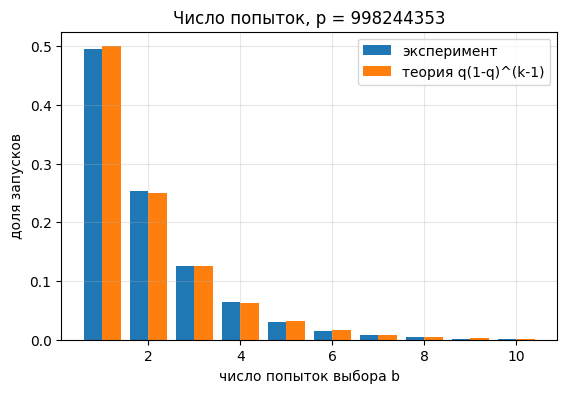

In [9]:
p = 998244353
rnd = random.Random(3)
runs = 20000
counts = {}
for _ in range(runs):
    inf = {}
    cipolla(rnd.randrange(1, p) ** 2 % p, p, rnd, inf)
    counts[inf["attempts"]] = counts.get(inf["attempts"], 0) + 1

mean = sum(k * v for k, v in counts.items()) / runs
q = (p - 1) / (2 * p)
print(f"запусков: {runs}, среднее число попыток: {mean:.3f}, теория 2p/(p-1) = {1 / q:.3f}")

ks = range(1, 11)
plt.figure(figsize=(6.4, 4))
plt.bar([k - 0.2 for k in ks], [counts.get(k, 0) / runs for k in ks], width=0.4, label="эксперимент")
plt.bar([k + 0.2 for k in ks], [q * (1 - q) ** (k - 1) for k in ks], width=0.4, label="теория q(1-q)^(k-1)")
plt.xlabel("число попыток выбора b"); plt.ylabel("доля запусков")
plt.title(f"Число попыток, p = {p}"); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 7. Сложность
Средняя трудоёмкость $O(\log^3 p)$: около двух символов Лежандра по $O(\log^3 p)$ каждый и $O(\log p)$ умножений в поле, каждое — $O(1)$ умножений по модулю $p$. Для сравнения возьмём явную формулу $x_0=a^{(p+1)/4}$ при $p\equiv3\pmod 4$ — тоже $O(\log^3 p)$.
Используем простые числа Мерсенна (все $\equiv 3 \pmod 4$), чтобы обе формулы были применимы.

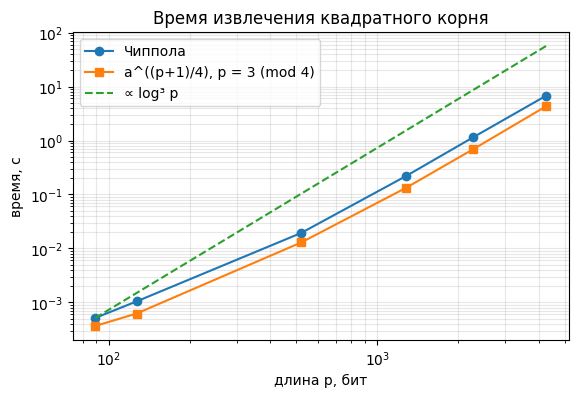

   89 бит: Чиппола     0.515 мс, формула     0.366 мс, отношение 1.4
  127 бит: Чиппола     1.047 мс, формула     0.624 мс, отношение 1.7
  521 бит: Чиппола    19.399 мс, формула    12.924 мс, отношение 1.5
 1279 бит: Чиппола   219.064 мс, формула   132.546 мс, отношение 1.7
 2281 бит: Чиппола  1152.581 мс, формула   692.775 мс, отношение 1.7
 4253 бит: Чиппола  6748.664 мс, формула  4302.573 мс, отношение 1.6


In [11]:
exps = [89, 127, 521, 1279, 2281, 4253]
t_cip, t_fml = [], []
rnd = random.Random(5)
for k in exps:
    p_ = 2**k - 1
    reps = 30 if k <= 521 else 8
    tests = [rnd.randrange(1, p_) ** 2 % p_ for _ in range(reps)]
    t = time.perf_counter()
    for a_ in tests: cipolla(a_, p_, rnd)
    t_cip.append((time.perf_counter() - t) / reps)
    t = time.perf_counter()
    for a_ in tests: sqrt_3mod4(a_, p_)
    t_fml.append((time.perf_counter() - t) / reps)

plt.figure(figsize=(6.4, 4))
plt.loglog(exps, t_cip, "o-", label="Чиппола")
plt.loglog(exps, t_fml, "s-", label="a^((p+1)/4), p = 3 (mod 4)")
plt.loglog(exps, [t_cip[0] * (e / exps[0]) ** 3 for e in exps], "--", label="∝ log³ p")
plt.xlabel("длина p, бит"); plt.ylabel("время, с")
plt.title("Время извлечения квадратного корня"); plt.legend(); plt.grid(alpha=.3, which="both")
plt.show()
for k, c, f in zip(exps, t_cip, t_fml):
    print(f"{k:5d} бит: Чиппола {c * 1000:9.3f} мс, формула {f * 1000:9.3f} мс, отношение {c / f:.1f}")

## Вывод

* Алгоритм Чипполы даёт верные корни для всех проверенных простых: малых, больших, с разными $p \bmod 8$ и с большой степенью двойки в $p-1$.
* Подходящее $b$ находится в среднем за две попытки, как и предсказывает теория ($(p-1)/2$ подходящих значений из $p$).
* Время растёт не круче $\log^3 p$ и отличается от явной формулы для $p\equiv3\pmod4$ лишь постоянным множителем; зато Чиппола работает при любом нечётном простом $p$.